<div style="background: linear-gradient(120deg, #1a3a5c 0%, #2d6a9f 60%, #4a9eda 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src='Figures/iteso.jpg' style='height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0;'/>
    <div style='border-left: 2px solid rgba(255,255,255,0.4); padding-left: 28px;'>
        <h1 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Ingeniería y Ciencia de Datos</h1>
        <h3 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Laboratorio de Procesamiento de Datos</h3>
        <h3 style='margin: 0; color: rgba(255,255,255,0.8); font-weight: normal; font-size: 1.05em;'>Módulo 2: Generación y transformación de datos</h3>
    </div>
</div>


## Enriquecimiento y creación de variables

Transformar datos no consiste únicamente en corregir errores o cambiar formatos. 

> También podemos **enriquecerlos**: agregar información útil o crear nuevas variables a partir de los datos disponibles. Por ejemplo, una fecha de nacimiento permite calcular una edad, una cantidad de visitas puede convertirse en una categoría (baja, media o alta), y una medida puede convertirse a otra unidad o escalarse.

Las variables derivadas pueden facilitar el análisis, apoyar reportes de **Business Intelligence (BI)** y preparar los datos para estudios posteriores o, más adelante, para modelos de inteligencia artificial. 

>Que una variable se pueda calcular no significa automáticamente que sea útil: debe responder a una pregunta y su definición debe poder explicarse.

**No existe una secuencia universal de generación de nuevos datos que se aplique igual a todos los proyectos.** Sin embargo, podemos usar un **proceso de trabajo** para tomar decisiones ordenadas, revisar los resultados y documentar cómo se crearon las variables. 
- Este proceso es iterativo: al validar el resultado podríamos necesitar ajustar la pregunta o la transformación.

1. **Definir el propósito.** ¿Qué pregunta queremos responder o qué decisión apoyará el análisis? Esto ayuda a elegir qué información realmente aporta valor.
2. **Revisar los datos disponibles.** Identificar columnas, tipos, unidades, valores faltantes, rangos y posibles inconsistencias. Confirmar qué significa cada campo con el contexto del problema.
3. **Elegir una estrategia de enriquecimiento.** Por ejemplo: calcular una variable (edad o importe total), agrupar valores en categorías, convertir unidades, escalar una medida o combinar la tabla con otra fuente confiable.
4. **Aplicar y nombrar las transformaciones.** Crear columnas nuevas con fórmulas claras y nombres descriptivos. Cuando sea útil, conservar las columnas originales para poder comparar y rastrear el cálculo.
5. **Validar el resultado.** Comprobar algunos cálculos manualmente, revisar tipos y rangos, contar valores faltantes y verificar que una unión de tablas no haya duplicado ni eliminado registros inesperadamente.
6. **Documentar y mantener.** Registrar fuente, fórmula, unidades, supuestos, fecha de referencia y limitaciones. Si los datos de origen cambian, definir cómo y cuándo se actualizan las variables.

```mermaid
flowchart TD
    A[Definir el propósito o pregunta] --> B[Revisar datos y contexto]
    B --> C[Elegir transformación o fuente adicional]
    C --> D[Crear variables, combinar o resumir]
    D --> E[Validar resultados]
    E --> F{¿Son correctos y útiles?}
    F -- Sí --> G[Documentar y utilizar]
    F -- No --> H[Revisar propósito, datos o regla]
    H --> B
```


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

carpeta_datos = 'Data'

## 1. Ejemplo Dummy

Usaremos algunos registros **sintéticos** de clientes y una tabla pequeña de actividad diaria de una cafetería. Sintético significa que los datos son inventados para practicar; no describen clientes ni un negocio reales.

En proyectos reales, las fechas, ventas y demás datos se obtendrían de los sistemas de la organización. La práctica se concentra en cómo enriquecerlos.

In [6]:
clientes = pd.DataFrame({
    'cliente_id': ['C001', 'C002', 'C003', 'C004', 'C005'],
    'fecha_nacimiento': pd.to_datetime([
        '2008-04-12', '1998-11-03', '1985-06-25',
        '1962-02-18', '2001-10-20'
    ])
})

clientes

,cliente_id,fecha_nacimiento
0,C001,2008-04-12
1,C002,1998-11-03
2,C003,1985-06-25
3,C004,1962-02-18
4,C005,2001-10-20


### 1.2. Crear una nueva variable

Crear la variable edad apartir de la fecha: La edad no siempre viene guardada en una tabla, pero puede calcularse a partir de la fecha de nacimiento. Primero elegimos una **fecha de referencia**. Para este ejemplo será el 22 de octubre de 2026, usar una fecha fija hace que el ejercicio noa de el mismo resultado cuando se vuelva a ejecutar.

No basta con restar los años: si la persona todavía no ha cumplido años en la fecha de referencia, debemos restar uno. La comparación del mes y día permite considerar ese detalle. 

- En pandas, `.dt.year`, `.dt.month` y `.dt.day` extraen esas partes de una columna de fechas. 

La edad calculada será una **variable derivada**

In [7]:
clientes['fecha_nacimiento']

0   2008-04-12
1   1998-11-03
2   1985-06-25
3   1962-02-18
4   2001-10-20
Name: fecha_nacimiento, dtype: datetime64[ns]

In [10]:
clientes['fecha_nacimiento'].dt.month

0     4
1    11
2     6
3     2
4    10
Name: fecha_nacimiento, dtype: int32

In [11]:
fecha_corte = pd.Timestamp('2026-10-20')
cumple_anos_pendiente = (
    (clientes['fecha_nacimiento'].dt.month > fecha_corte.month)
    | ((clientes['fecha_nacimiento'].dt.month == fecha_corte.month)& (clientes['fecha_nacimiento'].dt.day > fecha_corte.day))
)


In [12]:
cumple_anos_pendiente

0    False
1     True
2    False
3    False
4    False
Name: fecha_nacimiento, dtype: bool

In [13]:
clientes['edad'] = (
    fecha_corte.year
    - clientes['fecha_nacimiento'].dt.year
    - cumple_anos_pendiente.astype(int)
)

clientes

,cliente_id,fecha_nacimiento,edad
0,C001,2008-04-12,18
1,C002,1998-11-03,27
2,C003,1985-06-25,41
3,C004,1962-02-18,64
4,C005,2001-10-20,25


### 1.3. Agrupar valores en categorías

A veces es más fácil resumir o comunicar una cantidad mediante grupos. `pd.cut` divide una columna numérica en intervalos. En este ejemplo agruparemos las edades, los límites son decisiones que deben elegirse según el contexto, no reglas universales. Por defecto, cada intervalo incluye su límite derecho, `include_lowest=True` también incluye el valor más bajo del primer intervalo.

In [14]:
limites_edad = [0, 17, 30, 60, 120]
etiquetas_edad = ['0-17', '18-30', '31-60', '61 o más']

clientes['grupo_edad'] = pd.cut(
    clientes['edad'],
    bins=limites_edad,
    labels=etiquetas_edad,
    include_lowest=True
)

display(clientes)
print('Cantidad de clientes en cada grupo:')
display(clientes['grupo_edad'].value_counts(sort=False))

,cliente_id,fecha_nacimiento,edad,grupo_edad
0,C001,2008-04-12,18,18-30
1,C002,1998-11-03,27,18-30
2,C003,1985-06-25,41,31-60
3,C004,1962-02-18,64,61 o más
4,C005,2001-10-20,25,18-30


Cantidad de clientes en cada grupo:


grupo_edad
0-17        0
18-30       3
31-60       1
61 o más    1
Name: count, dtype: int64

## 2. Dataset: pingüinos de Palmer

Ahora aplicaremos las mismas ideas a un conjunto de datos publicado en la web. **Palmer Penguins** contiene mediciones de pingüinos observados en tres islas del archipiélago Palmer, en la Antártida. El conjunto tiene **344** registros e incluye especie, isla, longitud y profundidad del pico, longitud de la aleta, masa corporal, sexo y año.

Fuentes: [repositorio Palmer Penguins](https://github.com/allisonhorst/palmerpenguins), [archivo CSV utilizado](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv).

Primero revisaremos las columnas y los valores faltantes. 


In [16]:
pinguinos = pd.read_csv(os.path.join(carpeta_datos, 'penguins.csv'))


In [17]:
pinguinos.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [18]:
pinguinos.shape

(344, 8)

In [19]:
pinguinos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [20]:
pinguinos.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [21]:
pinguinos.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

**Vamos a crear columnas que podrían facilitar la lectura y el resumen de los datos:**

- `body_mass_kg`: convierte la masa de gramos a kilogramos (`gramos / 1000`).
- `flipper_length_cm`: convierte la longitud de la aleta de milímetros a centímetros (`milímetros / 10`).
- `bill_length_depth_ratio`: divide la longitud del pico entre su profundidad. Es un **índice calculado**.
- `bill_length_group`: agruparemos la longitud del pico en intervalos ilustrativos. 
- `body_mass_zscore`: expresa la masa en relación con el promedio de esta muestra. Un valor positivo está por encima del promedio y uno negativo, por debajo.

In [24]:
pinguinos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007


In [22]:
pinguinos_enriquecidos = pinguinos.copy()

In [25]:
#Nuevas columnas
pinguinos_enriquecidos['body_mass_kg'] = pinguinos_enriquecidos['body_mass_g']/1000
pinguinos_enriquecidos['body_mass_kg'] 

0      3.750
1      3.800
2      3.250
3        NaN
4      3.450
       ...  
339    4.000
340    3.400
341    3.775
342    4.100
343    3.775
Name: body_mass_kg, Length: 344, dtype: float64

In [27]:
pinguinos_enriquecidos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25


In [28]:
pinguinos_enriquecidos['bill_length_cm'] = pinguinos_enriquecidos['bill_length_mm'] /10
pinguinos_enriquecidos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_length_cm
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,3.91
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,3.95
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,4.03


In [29]:
pinguinos_enriquecidos['bill_length_depth_ratio'] = pinguinos_enriquecidos['bill_length_mm'] /  pinguinos_enriquecidos['bill_depth_mm'] 
pinguinos_enriquecidos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_length_cm,bill_length_depth_ratio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,3.91,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,3.95,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,4.03,2.238889


In [32]:
# StandardScaler
z_scores = (pinguinos_enriquecidos['body_mass_g'] - pinguinos_enriquecidos['body_mass_g'].mean())/(pinguinos_enriquecidos['body_mass_g'].std())
pinguinos_enriquecidos['body_mass_zscore'] = z_scores
pinguinos_enriquecidos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_length_cm,bill_length_depth_ratio,body_mass_zscore
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,3.91,2.090909,-0.563317
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,3.95,2.270115,-0.500969
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,4.03,2.238889,-1.186793


In [33]:
#pd.cut
pinguinos_enriquecidos['bill_length_group'] = pd.cut(pinguinos_enriquecidos['bill_length_mm'], bins=[0, 35, 45, float('inf')], 
                                                     labels=['corto', 'medio', 'largo'], include_lowest = True)
pinguinos_enriquecidos.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg,bill_length_cm,bill_length_depth_ratio,body_mass_zscore,bill_length_group
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75,3.91,2.090909,-0.563317,medio
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80,3.95,2.270115,-0.500969,medio
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25,4.03,2.238889,-1.186793,medio


In [35]:
pinguinos_enriquecidos['bill_length_group'].value_counts()

bill_length_group
medio    166
largo    165
corto     11
Name: count, dtype: int64

In [36]:
#Columnas estadisticas
pinguinos_enriquecidos.shape

(344, 13)

In [37]:
pinguinos_enriquecidos.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,body_mass_kg,bill_length_cm,bill_length_depth_ratio,body_mass_zscore
count,342.000000,342.000000,342.000000,342.000000,344.000000,342.000000,342.000000,342.000000,3.420000e+02
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070,4.201754,4.392193,2.605649,4.155221e-17
std,5.459584,1.974793,14.061714,801.954536,0.818356,0.801955,0.545958,0.497375,1.000000e+00
min,32.100000,13.100000,172.000000,2700.000000,2007.000000,2.700000,3.210000,1.639810,-1.872618e+00
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000,3.550000,3.922500,2.160344,-8.127074e-01
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000,4.050000,4.445000,2.575067,-1.892307e-01
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000,4.750000,4.850000,3.098777,6.836368e-01
max,59.600000,21.500000,231.000000,6300.000000,2009.000000,6.300000,5.960000,3.612676,2.616415e+00


In [38]:
#Valores faltantes
pinguinos_enriquecidos.isna().sum()

species                     0
island                      0
bill_length_mm              2
bill_depth_mm               2
flipper_length_mm           2
body_mass_g                 2
sex                        11
year                        0
body_mass_kg                2
bill_length_cm              2
bill_length_depth_ratio     2
body_mass_zscore            2
bill_length_group           2
dtype: int64

Además de crear columnas para cada pingüino, podemos **generar una nueva tabla** que resuma la información por especie e isla. `groupby` reúne las filas de cada combinación y `agg` calcula medidas para cada grupo. Esta tabla podría servir como punto de partida para un reporte de BI.

In [41]:
#Reporte con algunas métricas
resumen_pinguinos = (
    pinguinos_enriquecidos.groupby(['species','island'], as_index=False, observed=True).agg(registros=('species', 'size'), 
                                                                                             mediciones_masa = ('body_mass_kg', 'count'),
                                                                                           aleta_promedio_mm = ('flipper_length_mm', 'mean'))
)
resumen_pinguinos

,species,island,registros,mediciones_masa,aleta_promedio_mm
0,Adelie,Biscoe,44,44,188.795455
1,Adelie,Dream,56,56,189.732143
2,Adelie,Torgersen,52,51,191.196078
3,Chinstrap,Dream,68,68,195.823529
4,Gentoo,Biscoe,124,123,217.186992


Generar algunas gráficas

## 3. Enriquecer datos de alquiler de bicicletas

En este ejemplo trabajaremos con el conjunto **Bike Sharing Dataset** (`hour.csv`) extraído del repositorio [archivo original de UCI](https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip). La descripción original de las columnas está en `Data/bike_sharing_Readme.txt`. Este dataset contiene registros reales por hora del sistema **Capital Bikeshare** en Washington, D. C., durante 2011 y 2012, junto con información de calendario y clima. Cada fila representa una hora e incluye, entre otras columnas, fecha, estación, clima, temperatura normalizada, humedad, velocidad del viento y cantidad de bicicletas rentadas.

**¿Cómo podemos preparar estos registros para explorar la demanda por hora, periodo del día, tipo de día, estación del año y condiciones meteorológicas?**

- Para esto vamos a crear variables más interpretables que aporten valor para un análisis más comprensible.

In [43]:
bicicletas_original = pd.read_csv(os.path.join(carpeta_datos, 'hour.csv'))
bicicletas_original.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [44]:
bicicletas_original.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Algunas columnas están codificadas como números, pero representan categorías. Según la [descripción de UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset):

- `season`: 1 invierno, 2 primavera, 3 verano, 4 otoño.
- `weathersit`: 1 despejado o parcialmente nublado, 2 neblina o nubes, 3 nieve o lluvia ligera, 4 condiciones severas.
- `temp` está normalizada entre 0 y 1 a partir de una temperatura en °C entre -8 y 39. `atemp` usa una escala distinta, entre -16 y 50 °C.
- `hum` es humedad dividida entre 100.
- `casual` y `registered` son conteos de usuarios, `cnt` es el total de alquileres.

No debemos tratar el código `season=1` como una medida numérica: el número identifica una categoría. Usaremos etiquetas para que las tablas sean más legibles.

In [45]:
columnas_conteos = ['casual', 'registered', 'cnt']
diferencia_conteos = (
    bicicletas_original['casual']
    + bicicletas_original['registered']
    - bicicletas_original['cnt']
)

print('Filas duplicadas por fecha y hora:', bicicletas_original.duplicated(['dteday', 'hr']).sum())
print('Filas donde casual + registered no coincide con cnt:', (diferencia_conteos != 0).sum())
print('\nRangos de algunas columnas:')
bicicletas_original[columnas_conteos + ['temp', 'atemp', 'hum', 'windspeed']].describe().round(2)

Filas duplicadas por fecha y hora: 0
Filas donde casual + registered no coincide con cnt: 0

Rangos de algunas columnas:


,casual,registered,cnt,temp,atemp,hum,windspeed
count,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,35.68,153.79,189.46,0.50,0.48,0.63,0.19
std,49.31,151.36,181.39,0.19,0.17,0.19,0.12
min,0.00,0.00,1.00,0.02,0.00,0.00,0.00
25%,4.00,34.00,40.00,0.34,0.33,0.48,0.10
50%,17.00,115.00,142.00,0.50,0.48,0.63,0.19
75%,48.00,220.00,281.00,0.66,0.62,0.78,0.25
max,367.00,886.00,977.00,1.00,1.00,1.00,0.85


A partir de la fecha y la hora construiremos el momento completo (`fecha_hora`), el nombre del día, si corresponde a fin de semana y un periodo del día. También convertiremos las escalas normalizadas a sus unidades descritas por UCI y traduciremos los códigos de estación y clima.

Crearemos `periodo_dia`donde: madrugada (00–05), mañana (06–11), tarde (12–17) y noche (18–23). No son una clasificación universal es una elección que hacemos. La columna original se conserva y las variables derivadas se agregan a una copia.

In [47]:
bicicletas_original['dteday']

0        2011-01-01
1        2011-01-01
2        2011-01-01
3        2011-01-01
4        2011-01-01
            ...    
17374    2012-12-31
17375    2012-12-31
17376    2012-12-31
17377    2012-12-31
17378    2012-12-31
Name: dteday, Length: 17379, dtype: object

In [49]:
pd.to_datetime(bicicletas_original['dteday'])

0       2011-01-01
1       2011-01-01
2       2011-01-01
3       2011-01-01
4       2011-01-01
           ...    
17374   2012-12-31
17375   2012-12-31
17376   2012-12-31
17377   2012-12-31
17378   2012-12-31
Name: dteday, Length: 17379, dtype: datetime64[ns]

In [50]:
bicicletas = bicicletas_original.copy()
bicicletas['fecha'] = pd.to_datetime(bicicletas['dteday'])
bicicletas['fecha_hora'] = bicicletas['fecha'] + pd.to_timedelta(bicicletas['hr'], unit='h')
bicicletas['nombre_dia'] = bicicletas['fecha'].dt.day_name()
bicicletas['es_fin_de_semana'] = bicicletas['fecha'].dt.dayofweek.isin([5, 6])

bicicletas['periodo_dia'] = pd.cut(
    bicicletas['hr'],
    bins=[0, 6, 12, 18, 24],
    labels=['Madrugada', 'Mañana', 'Tarde', 'Noche'],
    right=False,
    include_lowest=True
)


In [51]:
bicicletas.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,hum,windspeed,casual,registered,cnt,fecha,fecha_hora,nombre_dia,es_fin_de_semana,periodo_dia
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,0.81,0.0,3,13,16,2011-01-01,2011-01-01 00:00:00,Saturday,True,Madrugada
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,0.80,0.0,8,32,40,2011-01-01,2011-01-01 01:00:00,Saturday,True,Madrugada
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,0.80,0.0,5,27,32,2011-01-01,2011-01-01 02:00:00,Saturday,True,Madrugada
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,0.75,0.0,3,10,13,2011-01-01,2011-01-01 03:00:00,Saturday,True,Madrugada
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,0.75,0.0,0,1,1,2011-01-01,2011-01-01 04:00:00,Saturday,True,Madrugada


In [52]:
etiquetas_estacion = {
    1: 'Invierno', 2: 'Primavera', 3: 'Verano', 4: 'Otoño'
}
etiquetas_clima = {
    1: 'Despejado o parcialmente nublado',
    2: 'Neblina o nublado',
    3: 'Nieve o lluvia ligera',
    4: 'Condiciones severas'
}

In [53]:
bicicletas['estacion_nombre'] = bicicletas['season'].map(etiquetas_estacion)
bicicletas['clima_nombre'] = bicicletas['weathersit'].map(etiquetas_clima)

#Conversion a grados c
bicicletas['temperatura_c'] = bicicletas['temp'] * (39 - (-8)) + (-8)
bicicletas['sensacion_termica_c'] = bicicletas['atemp'] * (50 - (-16)) + (-16)

bicicletas['humedad_pct'] = bicicletas['hum'] * 100

bicicletas['proporcion_usuarios_registrados'] = (
    bicicletas['registered'] / bicicletas['cnt'].where(bicicletas['cnt'] != 0)
)


In [54]:
columnas_nuevas = [
    'fecha_hora', 'nombre_dia', 'es_fin_de_semana', 'periodo_dia',
    'estacion_nombre', 'clima_nombre', 'temperatura_c',
    'sensacion_termica_c', 'humedad_pct', 'proporcion_usuarios_registrados'
]
bicicletas[['dteday', 'hr', 'season', 'weathersit', 'cnt'] + columnas_nuevas].head(12).round(2)

,dteday,hr,season,weathersit,cnt,fecha_hora,nombre_dia,es_fin_de_semana,periodo_dia,estacion_nombre,clima_nombre,temperatura_c,sensacion_termica_c,humedad_pct,proporcion_usuarios_registrados
0,2011-01-01,0,1,1,16,2011-01-01 00:00:00,Saturday,True,Madrugada,Invierno,Despejado o parcialmente nublado,3.28,3.0,81.0,0.81
1,2011-01-01,1,1,1,40,2011-01-01 01:00:00,Saturday,True,Madrugada,Invierno,Despejado o parcialmente nublado,2.34,2.0,80.0,0.80
2,2011-01-01,2,1,1,32,2011-01-01 02:00:00,Saturday,True,Madrugada,Invierno,Despejado o parcialmente nublado,2.34,2.0,80.0,0.84
3,2011-01-01,3,1,1,13,2011-01-01 03:00:00,Saturday,True,Madrugada,Invierno,Despejado o parcialmente nublado,3.28,3.0,75.0,0.77
4,2011-01-01,4,1,1,1,2011-01-01 04:00:00,Saturday,True,Madrugada,Invierno,Despejado o parcialmente nublado,3.28,3.0,75.0,1.00
5,2011-01-01,5,1,2,1,2011-01-01 05:00:00,Saturday,True,Madrugada,Invierno,Neblina o nublado,3.28,1.0,75.0,1.00
6,2011-01-01,6,1,1,2,2011-01-01 06:00:00,Saturday,True,Mañana,Invierno,Despejado o parcialmente nublado,2.34,2.0,80.0,0.00
7,2011-01-01,7,1,1,3,2011-01-01 07:00:00,Saturday,True,Mañana,Invierno,Despejado o parcialmente nublado,1.40,1.0,86.0,0.67
8,2011-01-01,8,1,1,8,2011-01-01 08:00:00,Saturday,True,Mañana,Invierno,Despejado o parcialmente nublado,3.28,3.0,75.0,0.88
9,2011-01-01,9,1,1,14,2011-01-01 09:00:00,Saturday,True,Mañana,Invierno,Despejado o parcialmente nublado,7.04,7.0,76.0,0.43


**Una variable derivada puede enriquecer cada fila** una **tabla agregada** resume varias filas. Aquí generaremos dos productos sencillos: la demanda promedio por hora y una tabla diaria. 

- `mean` contesta cuánto se renta en una hora típica de ese grupo
- `sum` permite calcular el total observado en el día. 

In [55]:
demanda_por_hora = (
    bicicletas
    .groupby('hr', as_index=False, observed=True)
    .agg(
        alquileres_promedio=('cnt', 'mean'),
        casuales_promedio=('casual', 'mean'),
        registrados_promedio=('registered', 'mean')
    )
)


In [56]:
demanda_por_periodo = (
    bicicletas
    .groupby(['es_fin_de_semana', 'periodo_dia'], as_index=False, observed=True)
    .agg(
        horas_observadas=('cnt', 'size'),
        alquileres_promedio=('cnt', 'mean'),
        humedad_promedio_pct=('humedad_pct', 'mean')
    )
)


In [57]:
resumen_diario = (
    bicicletas
    .groupby('fecha', as_index=False)
    .agg(
        alquileres_total=('cnt', 'sum'),
        usuarios_casuales_total=('casual', 'sum'),
        usuarios_registrados_total=('registered', 'sum'),
        horas_con_registro=('hr', 'nunique'),
        temperatura_promedio_c=('temperatura_c', 'mean')
    )
)


In [58]:
print('Promedio de alquileres por hora del día:')
display(demanda_por_hora.round(1))

Promedio de alquileres por hora del día:


,hr,alquileres_promedio,casuales_promedio,registrados_promedio
0,0,53.9,10.2,43.7
1,1,33.4,6.5,26.9
2,2,22.9,4.8,18.1
3,3,11.7,2.7,9.0
4,4,6.4,1.3,5.1
5,5,19.9,1.4,18.5
6,6,76.0,4.2,71.9
7,7,212.1,11.1,201.0
8,8,359.0,21.7,337.3
9,9,219.3,30.9,188.4


In [59]:
print('Comparación por fin de semana y periodo:')
display(demanda_por_periodo.round(1))

Comparación por fin de semana y periodo:


,es_fin_de_semana,periodo_dia,horas_observadas,alquileres_promedio,humedad_promedio_pct
0,False,Madrugada,3034,16.8,72.8
1,False,Mañana,3102,230.8,67.2
2,False,Tarde,3115,267.9,50.8
3,False,Noche,3114,247.1,61.0
4,True,Madrugada,1242,44.7,70.3
5,True,Mañana,1258,152.1,66.9
6,True,Tarde,1260,363.7,50.8
7,True,Noche,1254,172.8,61.5


In [60]:
print('Primeros registros del resumen diario:')
display(resumen_diario.head().round(1))

Primeros registros del resumen diario:


,fecha,alquileres_total,usuarios_casuales_total,usuarios_registrados_total,horas_con_registro,temperatura_promedio_c
0,2011-01-01,985,331,654,24,8.2
1,2011-01-02,801,131,670,23,9.1
2,2011-01-03,1349,120,1229,22,1.2
3,2011-01-04,1562,108,1454,23,1.4
4,2011-01-05,1600,82,1518,23,2.7


Las tablas permiten explorar cuándo se registraron más alquileres y comparar periodos o días. Son **descripciones de estos datos históricos**. Una diferencia entre días laborables y fines de semana no demuestra por sí sola que el tipo de día sea la causa: también pueden influir clima, eventos, disponibilidad de bicicletas y otros factores.


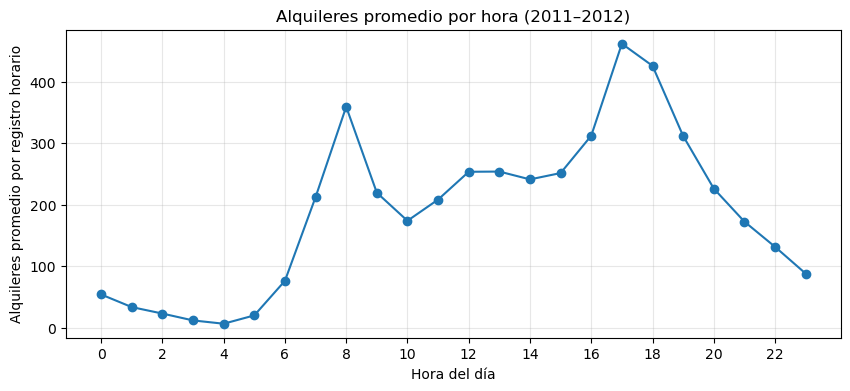

Resumen diario, en días con más alquileres:


,fecha,alquileres_total,usuarios_casuales_total,usuarios_registrados_total,horas_con_registro,temperatura_promedio_c
623,2012-09-15,8714,3160,5554,24,20.6
637,2012-09-29,8555,2589,5966,24,17.5
630,2012-09-22,8395,2512,5883,24,22.6
447,2012-03-23,8362,2469,5893,24,20.3
504,2012-05-19,8294,3410,4884,24,20.2


In [61]:
plt.figure(figsize=(10, 4))
plt.plot(demanda_por_hora['hr'], demanda_por_hora['alquileres_promedio'], marker='o')
plt.title('Alquileres promedio por hora (2011–2012)')
plt.xlabel('Hora del día')
plt.ylabel('Alquileres promedio por registro horario')
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

print('Resumen diario, en días con más alquileres:')
display(resumen_diario.nlargest(5, 'alquileres_total').round(1))

## 4. Enriquecer registros con contexto geográfico y demográfico

Leeremos las tres respuestas JSON del Banco Mundial guardadas en `Data`. Conservamos las respuestas originales para mantener los metadatos de las fuentes.

Un negocio puede tener registros de actividad asociados a un país o región y querer agregar contexto para un reporte. En lugar de usar direcciones de personas, aquí trabajaremos con **códigos ISO de país** y datos públicos agregados del Banco Mundial. 

- Haremos una unión mediante una clave geográfica común, igual que se podría relacionar un registro con una tabla de ciudades, estados o códigos postales cuando el nivel y el uso sean apropiados.

- Usaremos indicadores del año **2023**: población total (`SP.POP.TOTL`), PIB per cápita en dólares corrientes (`NY.GDP.PCAP.CD`) y región/nivel de ingreso del catálogo de países. Estos valores describen países o economías.

La tabla de compras y sus importes son datos dummys creados para este ejercicio. La fuente real que agregamos es la información geográfica y económica del Banco Mundial. 

Fuentes: [API de países del Banco Mundial](https://api.worldbank.org/v2/country?format=json&per_page=300), [indicador de población](https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?date=2023&format=json&per_page=300) e [indicador de PIB per cápita](https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD?date=2023&format=json&per_page=300).

In [ ]:
import json

def leer_datos_banco_mundial(archivo):
    with open(archivo, encoding='utf-8') as entrada:
        contenido = json.load(entrada)
    if len(contenido) < 2 or contenido[1] is None:
        raise ValueError(f'El archivo no contiene datos del Banco Mundial: {archivo}')
    return contenido[1]

paises_api = leer_datos_banco_mundial(
    os.path.join(carpeta_datos, 'banco_mundial_paises.json')
)
poblacion_api = leer_datos_banco_mundial(
    os.path.join(carpeta_datos, 'banco_mundial_poblacion_2023.json')
)
pib_api = leer_datos_banco_mundial(
    os.path.join(carpeta_datos, 'banco_mundial_pib_per_capita_2023.json')
)

print('Registros de países recibidos:', len(paises_api))
print('Observaciones de población recibidas:', len(poblacion_api))
print('Observaciones de PIB per cápita recibidas:', len(pib_api))

### Preparar las tablas y unirlas por el código del país

Los archivos locales conservan las respuestas originales de la API en formato JSON, incluidos sus metadatos. Convertiremos cada respuesta a una tabla de pandas y dejaremos solo columnas necesarias. 

- El código de tres letras (por ejemplo, `MEX`) será nuestra **clave de unión**. Excluimos los agregados regionales del Banco Mundial porque el ejemplo asigna contexto a países individuales.

In [ ]:
tabla_paises = pd.DataFrame([
    {
        'pais_iso3': pais['id'],
        'pais': pais['name'],
        'region': pais['region']['value'].strip(),
        'nivel_ingreso_pais': pais['incomeLevel']['value'].strip(),
        'codigo_nivel_ingreso': pais['incomeLevel']['id']
    }
    for pais in paises_api
    if pais['incomeLevel']['id'] in {'LIC', 'LMC', 'UMC', 'HIC'}
])

codigos_pais = set(tabla_paises['pais_iso3'])

tabla_poblacion = pd.DataFrame([
    {'pais_iso3': dato['countryiso3code'], 'poblacion_2023': dato['value']}
    for dato in poblacion_api
    if dato['value'] is not None and dato['countryiso3code'] in codigos_pais
])

tabla_pib = pd.DataFrame([
    {'pais_iso3': dato['countryiso3code'], 'pib_per_capita_usd_2023': dato['value']}
    for dato in pib_api
    if dato['value'] is not None and dato['countryiso3code'] in codigos_pais
])

contexto_paises = (
    tabla_paises
    .merge(tabla_poblacion, on='pais_iso3', how='left', validate='one_to_one')
    .merge(tabla_pib, on='pais_iso3', how='left', validate='one_to_one')
)

display(contexto_paises[contexto_paises['pais_iso3'].isin(['MEX', 'USA', 'COL', 'BRA'])].round(2))

### Agregar contexto a una tabla de actividad

Ahora relacionamos cada registro con la tabla geográfica mediante `pais_iso3`. En un proyecto real, esa clave podría provenir de un país seleccionado por el usuario o de una dirección validada y convertida a una región con permisos adecuados. 

In [ ]:
compras_demo = pd.DataFrame({
    'registro_id': ['R001', 'R002', 'R003', 'R004', 'R005', 'R006'],
    'pais_iso3': ['MEX', 'USA', 'COL', 'BRA', 'MEX', 'USA'],
    'importe_compra_usd': [35.50, 82.00, 24.75, 51.20, 63.00, 45.00]
})

compras_enriquecidas = compras_demo.merge(
    contexto_paises,
    on='pais_iso3',
    how='left',
    validate='many_to_one',
    indicator=True
)

print('Registros antes de la unión:', len(compras_demo))
print('Registros después de la unión:', len(compras_enriquecidas))
print('Resultado de la unión:')
display(compras_enriquecidas[[
    'registro_id', 'pais_iso3', 'pais', 'region', 'nivel_ingreso_pais',
    'poblacion_2023', 'pib_per_capita_usd_2023', 'importe_compra_usd', '_merge'
]].round(2))

print('¿Algún código no encontró país?', (compras_enriquecidas['_merge'] != 'both').any())


**Idea clave:** enriquecer datos es crear variables útiles con reglas comprensibles, justificadas y documentadas.

## Práctica de Laboratorio
Para el dataset **Palmer Penguins**
1. Propón otra variable derivada que pudiera ayudar en un reporte y escribe en una frase cómo se calcularía y qué limitación tendría.

Usando el datset **Bike Sharing**, realizar lo siguiente:
1. Cambia los intervalos de `periodo_dia` y explica cómo cambia la tabla `demanda_por_periodo`.
2. Compara la cantidad promedio de usuarios casuales y registrados en `demanda_por_hora`. ¿En qué horas difieren más?
3. Crea una tabla que resuma los alquileres promedio por `estacion_nombre` y `clima_nombre`. Recuerda incluir el número de observaciones de cada grupo.
5. Propón una variable derivada adicional para planear la operación de bicicletas. Describe su fórmula, unidades y una limitación.

Usando las tres respuestas **JSON del Banco Mundial** y el datset **compras_demo**, realizar lo siguiente:

1. Cambia uno de los códigos `pais_iso3` de `compras_demo` por otro país que aparezca en `contexto_paises`. ¿Qué columnas se agregan?
2. Prueba un código que no exista y observa `_merge`. ¿Por qué es útil verificar si todas las filas encontraron correspondencia?